# 08 - Clean Skull and Brain 3D Reconstruction

This notebook reconstructs two aligned surfaces from the anonymized head CT:

- **Skull:** extracted from the sharp `BONE_HR60F` series.
- **Brain envelope:** extracted from the soft-tissue `BRAIN_HR36F` series.

Version 8 removes scanner-table pixels and small disconnected objects, retains
only the single connected intracranial brain component, smooths both meshes,
and displays every mesh triangle. This avoids the floating brain fragment and
the dotted/porous rendering created by face subsampling in the earlier view.

The brain result is an automated CT-derived visualization envelope. It is not a
clinically validated tissue segmentation and must not be used for diagnosis.

In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pydicom
import plotly.graph_objects as go
import trimesh
from scipy import ndimage as ndi
from skimage import measure
from skimage.morphology import disk

STARTED = time.time()
DATASET_ROOT = Path(r"F:\csstdy\Single_Patient_Study")
OUTPUT_DIR = Path(r"F:\csstdy\outputs\08_clean_skull_brain_reconstruction")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Half-resolution in-plane processing keeps execution short while preserving Z.
XY_DOWNSAMPLE = 2
Z_DOWNSAMPLE = 1
BONE_THRESHOLD_HU = 250.0
SOFT_TISSUE_RANGE_HU = (-10.0, 100.0)
MINIMUM_HEAD_DEPTH_MM = 7.0
INFERIOR_BRAIN_CROP_INDEX = 45
MARCHING_CUBES_STEP = 2
SKULL_SMOOTHING_ITERATIONS = 6
BRAIN_SMOOTHING_ITERATIONS = 12

assert DATASET_ROOT.exists(), f"Dataset not found: {DATASET_ROOT}"
print("Dataset:", DATASET_ROOT)
print("Output:", OUTPUT_DIR)

Dataset: F:\csstdy\Single_Patient_Study
Output: F:\csstdy\outputs\08_clean_skull_brain_reconstruction


## Load and align both CT reconstruction kernels

Files are sorted by physical DICOM geometry, not filename. The notebook also
checks that both reconstruction kernels have matching slice locations.

In [2]:
def load_series(series_name):
    folders = sorted(path for path in DATASET_ROOT.rglob(series_name) if path.is_dir())
    if not folders:
        raise FileNotFoundError(f"No {series_name} directory found below {DATASET_ROOT}")

    folder = folders[0]
    datasets = [pydicom.dcmread(path, force=True) for path in sorted(folder.glob("*.dcm"))]
    if len(datasets) < 3:
        raise RuntimeError(f"Too few DICOM slices in {folder}")

    first = datasets[0]
    orientation = np.asarray(first.ImageOrientationPatient, dtype=float)
    row_direction = orientation[:3]
    column_direction = orientation[3:]
    slice_normal = np.cross(row_direction, column_direction)
    slice_normal /= np.linalg.norm(slice_normal)

    locations = np.asarray([
        np.dot(np.asarray(ds.ImagePositionPatient, dtype=float), slice_normal)
        for ds in datasets
    ])
    order = np.argsort(locations)
    datasets = [datasets[index] for index in order]
    locations = locations[order]

    if len(np.unique(np.round(locations, 5))) != len(datasets):
        raise RuntimeError(f"Duplicate anatomical slice positions in {series_name}")
    differences = np.diff(locations)
    if not np.allclose(differences, np.median(differences), atol=1e-3):
        raise RuntimeError(f"Non-uniform slice positions in {series_name}")

    rows, columns = int(first.Rows), int(first.Columns)
    if not all(int(ds.Rows) == rows and int(ds.Columns) == columns for ds in datasets):
        raise RuntimeError(f"Inconsistent image matrix in {series_name}")

    volume = np.empty((len(datasets), rows, columns), dtype=np.float32)
    for index, ds in enumerate(datasets):
        volume[index] = (
            ds.pixel_array.astype(np.float32) * float(getattr(ds, "RescaleSlope", 1.0))
            + float(getattr(ds, "RescaleIntercept", 0.0))
        )

    spacing = (
        float(np.median(np.abs(differences))),
        float(first.PixelSpacing[0]),
        float(first.PixelSpacing[1]),
    )
    geometry = {
        "row_direction": row_direction,
        "column_direction": column_direction,
        "slice_normal": slice_normal,
        "origin": np.asarray(datasets[0].ImagePositionPatient, dtype=float),
    }
    return folder, datasets, locations, volume, spacing, geometry


brain_folder, brain_datasets, brain_locations, brain_hu, spacing, geometry = load_series(
    "BRAIN_HR36F"
)
bone_folder, bone_datasets, bone_locations, bone_hu, bone_spacing, bone_geometry = load_series(
    "BONE_HR60F"
)

if brain_hu.shape != bone_hu.shape:
    raise RuntimeError("Brain and bone series have different volume shapes")
if not np.allclose(brain_locations, bone_locations, atol=1e-3):
    raise RuntimeError("Brain and bone slices are not geometrically aligned")
if not np.allclose(spacing, bone_spacing, atol=1e-6):
    raise RuntimeError("Brain and bone series have different voxel spacing")

print("Brain series:", brain_folder.name)
print("Bone series:", bone_folder.name)
print("Volume shape:", brain_hu.shape)
print("Voxel spacing (slice, row, column) mm:", spacing)

Brain series: BRAIN_HR36F
Bone series: BONE_HR60F
Volume shape: (227, 512, 512)
Voxel spacing (slice, row, column) mm: (0.75, 0.55574609375, 0.55574609375)


## Derive clean skull and intracranial brain masks

In [3]:
def largest_2d(mask):
    labels, count = ndi.label(mask)
    if count == 0:
        return np.zeros_like(mask, dtype=bool)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    return labels == sizes.argmax()


def largest_3d(mask):
    labels, count = ndi.label(mask, structure=ndi.generate_binary_structure(3, 2))
    if count == 0:
        return np.zeros_like(mask, dtype=bool)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    return labels == sizes.argmax()


brain_work = brain_hu[::Z_DOWNSAMPLE, ::XY_DOWNSAMPLE, ::XY_DOWNSAMPLE]
bone_work = bone_hu[::Z_DOWNSAMPLE, ::XY_DOWNSAMPLE, ::XY_DOWNSAMPLE]
working_spacing = (
    spacing[0] * Z_DOWNSAMPLE,
    spacing[1] * XY_DOWNSAMPLE,
    spacing[2] * XY_DOWNSAMPLE,
)
brain_smooth = ndi.gaussian_filter(brain_work, sigma=(0.55, 0.70, 0.70))
bone_smooth = ndi.gaussian_filter(bone_work, sigma=(0.45, 0.60, 0.60))

# Select the patient's head on every slice. Filling the largest component
# excludes the CT table, positioning hardware, and isolated bright pixels.
head_mask = np.zeros_like(brain_work, dtype=bool)
for z in range(len(brain_work)):
    head_slice = largest_2d(brain_smooth[z] > -300.0)
    head_mask[z] = ndi.binary_fill_holes(
        ndi.binary_closing(head_slice, structure=disk(4))
    )

# Skull from the sharp bone kernel, restricted to the patient outline.
skull_mask = (bone_smooth >= BONE_THRESHOLD_HU) & ndi.binary_dilation(
    head_mask, structure=np.ones((1, 3, 3), dtype=bool)
)
skull_mask = ndi.binary_closing(
    skull_mask, structure=ndi.generate_binary_structure(3, 1), iterations=1
)
skull_labels, skull_component_count = ndi.label(
    skull_mask, structure=ndi.generate_binary_structure(3, 2)
)
skull_sizes = np.bincount(skull_labels.ravel())
skull_sizes[0] = 0
largest_skull_size = int(skull_sizes.max())
minimum_skull_component = max(250, int(largest_skull_size * 0.002))
kept_skull_labels = np.flatnonzero(skull_sizes >= minimum_skull_component)
skull_mask = np.isin(skull_labels, kept_skull_labels)

# Brain envelope from soft-tissue intensities at least 7 mm inside the head.
# Per-slice cleanup follows the intracranial soft tissue, including cerebellum.
brain_mask = np.zeros_like(brain_work, dtype=bool)
for z in range(len(brain_work)):
    depth_mm = ndi.distance_transform_edt(
        head_mask[z], sampling=working_spacing[1:]
    )
    candidate = (
        (depth_mm >= MINIMUM_HEAD_DEPTH_MM)
        & (brain_smooth[z] >= SOFT_TISSUE_RANGE_HU[0])
        & (brain_smooth[z] <= SOFT_TISSUE_RANGE_HU[1])
    )
    candidate = ndi.binary_opening(candidate, structure=disk(1))
    candidate = ndi.binary_closing(candidate, structure=disk(2))
    brain_mask[z] = ndi.binary_fill_holes(largest_2d(candidate))

# Exclude inferior face/neck, join adjacent brain slices, then retain exactly
# one 3-D component. This is the key change that removes the floating cap.
brain_mask[:INFERIOR_BRAIN_CROP_INDEX] = False
brain_mask = ndi.binary_closing(
    brain_mask, structure=ndi.generate_binary_structure(3, 2), iterations=1
)
brain_mask = largest_3d(brain_mask)
for z in range(len(brain_mask)):
    brain_mask[z] = ndi.binary_fill_holes(brain_mask[z])
brain_mask = ndi.binary_closing(
    brain_mask, structure=ndi.generate_binary_structure(3, 2), iterations=1
)
brain_mask = largest_3d(brain_mask)

if not skull_mask.any() or not brain_mask.any():
    raise RuntimeError("A derived reconstruction mask is empty")

brain_slice_areas = brain_mask.sum(axis=(1, 2))
brain_slices = np.flatnonzero(brain_slice_areas > 0)
voxel_volume_mm3 = float(np.prod(working_spacing))
brain_volume_ml = float(brain_mask.sum() * voxel_volume_mm3 / 1000.0)

print("Working shape:", brain_work.shape)
print("Skull components found / retained:", skull_component_count, "/", len(kept_skull_labels))
print("Skull voxels:", f"{int(skull_mask.sum()):,}")
print("Brain voxels:", f"{int(brain_mask.sum()):,}")
print("Brain axial span:", int(brain_slices[0]), "to", int(brain_slices[-1]))
print("Approximate brain-envelope volume:", f"{brain_volume_ml:.1f} mL")

Working shape: (227, 256, 256)
Skull components found / retained: 95 / 1
Skull voxels: 510,224
Brain voxels: 1,289,606
Brain axial span: 46 to 201
Approximate brain-envelope volume: 1194.9 mL


## Quality-control overlays

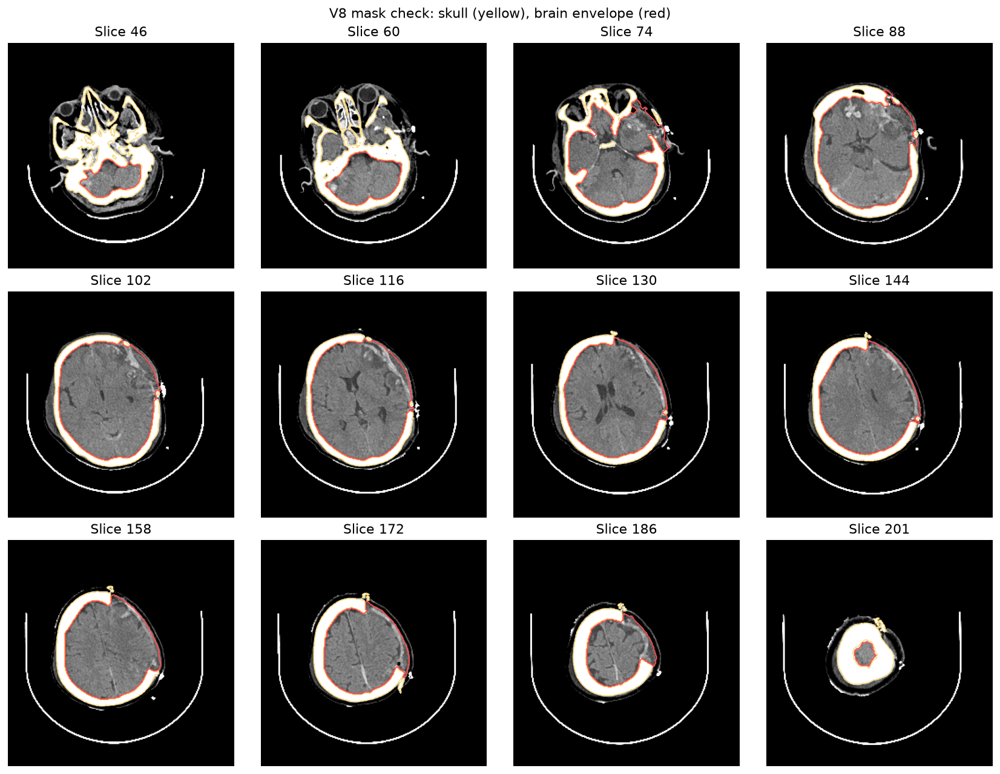

In [4]:
preview_indices = np.linspace(brain_slices[0], brain_slices[-1], 12, dtype=int)
qc_figure, axes = plt.subplots(3, 4, figsize=(13, 10), dpi=130)
for axis, z in zip(axes.ravel(), preview_indices):
    axis.imshow(brain_work[z], cmap="gray", vmin=-20, vmax=100)
    if skull_mask[z].any():
        axis.contour(
            skull_mask[z].astype(np.uint8), levels=[0.5],
            colors=["#f6d365"], linewidths=0.7
        )
    if brain_mask[z].any():
        axis.contour(
            brain_mask[z].astype(np.uint8), levels=[0.5],
            colors=["#ff4e50"], linewidths=1.0
        )
    axis.set_title(f"Slice {z}")
    axis.axis("off")

qc_figure.suptitle("V8 mask check: skull (yellow), brain envelope (red)")
qc_figure.tight_layout()
overlay_path = OUTPUT_DIR / "CASE_001_clean_masks_overlay.png"
qc_figure.savefig(overlay_path, bbox_inches="tight")
plt.show()

## Reconstruct and smooth the two surfaces

The marching-cubes step is intentionally set to 2 to reduce rendering time and
mesh noise. Taubin smoothing reduces voxel stair-stepping without the severe
shrinkage caused by ordinary Laplacian smoothing.

In [5]:
def mask_to_patient_mesh(mask, smoothing_iterations):
    padded = np.pad(mask.astype(np.uint8), 1, mode="constant")
    vertices_local, faces, _normals, _values = measure.marching_cubes(
        padded,
        level=0.5,
        spacing=working_spacing,
        step_size=MARCHING_CUBES_STEP,
        allow_degenerate=False,
    )
    vertices_local -= np.asarray(working_spacing)

    vertices_patient = (
        geometry["origin"]
        + np.outer(vertices_local[:, 0], geometry["slice_normal"])
        + np.outer(vertices_local[:, 1], geometry["column_direction"])
        + np.outer(vertices_local[:, 2], geometry["row_direction"])
    ).astype(np.float32)

    mesh = trimesh.Trimesh(
        vertices=vertices_patient, faces=faces, process=True, validate=True
    )
    mesh.remove_unreferenced_vertices()
    trimesh.smoothing.filter_taubin(
        mesh, lamb=0.50, nu=0.525, iterations=smoothing_iterations
    )
    mesh.fix_normals(multibody=True)
    return mesh


skull_mesh = mask_to_patient_mesh(skull_mask, SKULL_SMOOTHING_ITERATIONS)
brain_mesh = mask_to_patient_mesh(brain_mask, BRAIN_SMOOTHING_ITERATIONS)

skull_mesh.visual.face_colors = [232, 214, 179, 210]
brain_mesh.visual.face_colors = [217, 155, 145, 255]

print("Skull mesh:", f"{len(skull_mesh.vertices):,} vertices,", f"{len(skull_mesh.faces):,} triangles")
print("Brain mesh:", f"{len(brain_mesh.vertices):,} vertices,", f"{len(brain_mesh.faces):,} triangles")
print("Brain connected bodies:", len(brain_mesh.split(only_watertight=False)))

Skull mesh: 65,039 vertices, 132,086 triangles
Brain mesh: 25,371 vertices, 50,790 triangles
Brain connected bodies: 1


## Export individual models and a combined 3D scene

In [6]:
paths = {
    "skull_ply": OUTPUT_DIR / "CASE_001_clean_skull.ply",
    "skull_stl": OUTPUT_DIR / "CASE_001_clean_skull.stl",
    "skull_glb": OUTPUT_DIR / "CASE_001_clean_skull.glb",
    "brain_ply": OUTPUT_DIR / "CASE_001_clean_brain.ply",
    "brain_stl": OUTPUT_DIR / "CASE_001_clean_brain.stl",
    "brain_glb": OUTPUT_DIR / "CASE_001_clean_brain.glb",
    "combined_glb": OUTPUT_DIR / "CASE_001_clean_skull_and_brain.glb",
    "combined_html": OUTPUT_DIR / "CASE_001_clean_skull_and_brain.html",
    "skull_html": OUTPUT_DIR / "CASE_001_clean_skull_only.html",
    "brain_html": OUTPUT_DIR / "CASE_001_clean_brain_only.html",
    "summary": OUTPUT_DIR / "reconstruction_summary.json",
}

skull_mesh.export(paths["skull_ply"])
skull_mesh.export(paths["skull_stl"])
brain_mesh.export(paths["brain_ply"])
brain_mesh.export(paths["brain_stl"])

skull_scene = trimesh.Scene(skull_mesh)
brain_scene = trimesh.Scene(brain_mesh)
paths["skull_glb"].write_bytes(skull_scene.export(file_type="glb"))
paths["brain_glb"].write_bytes(brain_scene.export(file_type="glb"))

combined_scene = trimesh.Scene()
combined_scene.add_geometry(skull_mesh.copy(), node_name="skull", geom_name="skull")
combined_scene.add_geometry(brain_mesh.copy(), node_name="brain", geom_name="brain")
paths["combined_glb"].write_bytes(combined_scene.export(file_type="glb"))

skull_vertices = np.asarray(skull_mesh.vertices)
skull_faces = np.asarray(skull_mesh.faces)
brain_vertices = np.asarray(brain_mesh.vertices)
brain_faces = np.asarray(brain_mesh.faces)

# All triangles are displayed. We do not sample individual faces, because doing
# so creates the black dotted holes visible in the previous reconstruction.
figure_3d = go.Figure([
    go.Mesh3d(
        x=skull_vertices[:, 0], y=skull_vertices[:, 1], z=skull_vertices[:, 2],
        i=skull_faces[:, 0], j=skull_faces[:, 1], k=skull_faces[:, 2],
        name="Skull", color="#e8d6b3", opacity=0.24,
        flatshading=False, hoverinfo="skip",
        lighting=dict(ambient=0.48, diffuse=0.65, specular=0.16, roughness=0.78),
    ),
    go.Mesh3d(
        x=brain_vertices[:, 0], y=brain_vertices[:, 1], z=brain_vertices[:, 2],
        i=brain_faces[:, 0], j=brain_faces[:, 1], k=brain_faces[:, 2],
        name="Brain envelope", color="#d99b91", opacity=1.0,
        flatshading=False, hoverinfo="skip",
        lighting=dict(ambient=0.44, diffuse=0.72, specular=0.18, roughness=0.78),
    ),
])
figure_3d.update_layout(
    title="CASE_001 - Clean Skull and Brain Reconstruction",
    template="plotly_dark",
    width=950,
    height=780,
    margin=dict(l=0, r=0, t=60, b=0),
    legend=dict(x=0.02, y=0.98),
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)",
        yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False),
        camera=dict(eye=dict(x=1.55, y=-1.55, z=1.15)),
    ),
)
figure_3d.write_html(paths["combined_html"], include_plotlyjs=True, full_html=True)
figure_3d.show()

summary = {
    "source_series": {"brain": brain_folder.name, "skull": bone_folder.name},
    "source_slices": len(brain_datasets),
    "source_shape": list(brain_hu.shape),
    "voxel_spacing_mm": list(spacing),
    "working_shape": list(brain_work.shape),
    "mask_parameters": {
        "bone_threshold_hu": BONE_THRESHOLD_HU,
        "soft_tissue_range_hu": list(SOFT_TISSUE_RANGE_HU),
        "minimum_head_depth_mm": MINIMUM_HEAD_DEPTH_MM,
        "brain_component_rule": "single largest connected 3-D component",
    },
    "brain_envelope_volume_ml": brain_volume_ml,
    "skull_mesh": {
        "vertices": int(len(skull_mesh.vertices)),
        "triangles": int(len(skull_mesh.faces)),
        "watertight": bool(skull_mesh.is_watertight),
    },
    "brain_mesh": {
        "vertices": int(len(brain_mesh.vertices)),
        "triangles": int(len(brain_mesh.faces)),
        "watertight": bool(brain_mesh.is_watertight),
        "connected_bodies": int(len(brain_mesh.split(only_watertight=False))),
    },
    "outputs": {name: str(path) for name, path in paths.items() if name != "summary"},
    "overlay_path": str(overlay_path),
    "elapsed_seconds": time.time() - STARTED,
    "validated_clinical_segmentation": False,
}
paths["summary"].write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "source_series": {
    "brain": "BRAIN_HR36F",
    "skull": "BONE_HR60F"
  },
  "source_slices": 227,
  "source_shape": [
    227,
    512,
    512
  ],
  "voxel_spacing_mm": [
    0.75,
    0.55574609375,
    0.55574609375
  ],
  "working_shape": [
    227,
    256,
    256
  ],
  "mask_parameters": {
    "bone_threshold_hu": 250.0,
    "soft_tissue_range_hu": [
      -10.0,
      100.0
    ],
    "minimum_head_depth_mm": 7.0,
    "brain_component_rule": "single largest connected 3-D component"
  },
  "brain_envelope_volume_ml": 1194.8988340822561,
  "skull_mesh": {
    "vertices": 65039,
    "triangles": 132086,
    "watertight": false
  },
  "brain_mesh": {
    "vertices": 25371,
    "triangles": 50790,
    "watertight": true,
    "connected_bodies": 1
  },
  "outputs": {
    "skull_ply": "F:\\csstdy\\outputs\\08_clean_skull_brain_reconstruction\\CASE_001_clean_skull.ply",
    "skull_stl": "F:\\csstdy\\outputs\\08_clean_skull_brain_reconstruction\\CASE_001_clean_skull.stl",
    

In [7]:
# Separate interactive skull view
skull_only_figure = go.Figure([
    go.Mesh3d(
        x=skull_vertices[:, 0], y=skull_vertices[:, 1], z=skull_vertices[:, 2],
        i=skull_faces[:, 0], j=skull_faces[:, 1], k=skull_faces[:, 2],
        name="Skull", color="#e8d6b3", opacity=1.0,
        flatshading=False, hoverinfo="skip",
        lighting=dict(ambient=0.42, diffuse=0.72, specular=0.20, roughness=0.72),
    )
])
skull_only_figure.update_layout(
    title="CASE_001 - Clean Skull Reconstruction",
    template="plotly_dark", width=950, height=780,
    margin=dict(l=0, r=0, t=60, b=0),
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)",
        yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False),
        camera=dict(eye=dict(x=1.55, y=-1.55, z=1.15)),
    ),
)
skull_only_figure.write_html(paths["skull_html"], include_plotlyjs=True, full_html=True)
skull_only_figure.show()

In [8]:
# Separate interactive brain-envelope view
brain_only_figure = go.Figure([
    go.Mesh3d(
        x=brain_vertices[:, 0], y=brain_vertices[:, 1], z=brain_vertices[:, 2],
        i=brain_faces[:, 0], j=brain_faces[:, 1], k=brain_faces[:, 2],
        name="Brain envelope", color="#d99b91", opacity=1.0,
        flatshading=False, hoverinfo="skip",
        lighting=dict(ambient=0.44, diffuse=0.72, specular=0.18, roughness=0.78),
    )
])
brain_only_figure.update_layout(
    title="CASE_001 - Clean Brain-Envelope Reconstruction",
    template="plotly_dark", width=950, height=780,
    margin=dict(l=0, r=0, t=60, b=0),
    scene=dict(
        aspectmode="data",
        xaxis_title="Patient X (mm)",
        yaxis_title="Patient Y (mm)",
        zaxis_title="Patient Z (mm)",
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False),
        camera=dict(eye=dict(x=1.55, y=-1.55, z=1.15)),
    ),
)
brain_only_figure.write_html(paths["brain_html"], include_plotlyjs=True, full_html=True)
brain_only_figure.show()